<center><h1>Groome_Henry_HW4</h1></center>
<br>
<br>

Name: Henry Groome
<br>
Github Username: hgroome46
<br>
USC ID: 4479346040

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [19]:
import os
import numpy as np
import pandas as pd

Get the AReM Data Set

In [20]:
data_dir = 'AReM'


cols = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13',
        'var_rss13', 'avg_rss23', 'var_rss23']

activities = sorted(d for d in os.listdir(data_dir)
                    if os.path.isdir(os.path.join(data_dir, d)))
print(activities)

instances = []
for activity in activities:
    folder = os.path.join(data_dir, activity)
    for fname in sorted(os.listdir(folder)):
        if not fname.endswith('.csv'):
            continue
        num = int(fname.replace('dataset', '').replace('.csv', ''))
        df = pd.read_csv(os.path.join(folder, fname), skiprows=5, names=cols,
                         usecols=range(7), sep=r'[,\s]+', engine='python')
        instances.append({'activity': activity, 'num': num, 'data': df})

print(len(instances), 'files loaded')

['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
88 files loaded


### (b) Splitting Data

In [21]:
def is_test(activity, num):
    if activity in ('bending1', 'bending2'):
        return num <= 2
    return num <= 3

for inst in instances:
    inst['split'] = 'test' if is_test(inst['activity'], inst['num']) else 'train'

print(pd.Series([i['split'] for i in instances]).value_counts())

train    69
test     19
Name: count, dtype: int64


### (c) Feature Extraction

In [22]:
series = cols[1:]   

rows = []
for inst in instances:
    df = inst['data']
    row = {'activity': inst['activity'], 'num': inst['num'], 'split': inst['split']}
    for i, s in enumerate(series, start=1):
        x = df[s]
        row[f'min{i}']       = x.min()
        row[f'max{i}']       = x.max()
        row[f'mean{i}']      = x.mean()
        row[f'median{i}']    = x.median()
        row[f'std{i}']       = x.std()
        row[f'1st_quart{i}'] = x.quantile(0.25)
        row[f'3rd_quart{i}'] = x.quantile(0.75)
    rows.append(row)

features = pd.DataFrame(rows)
features.index = range(1, len(features) + 1)
features.head()

,activity,num,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
1,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

bending
False    60
True      9
Name: count, dtype: int64


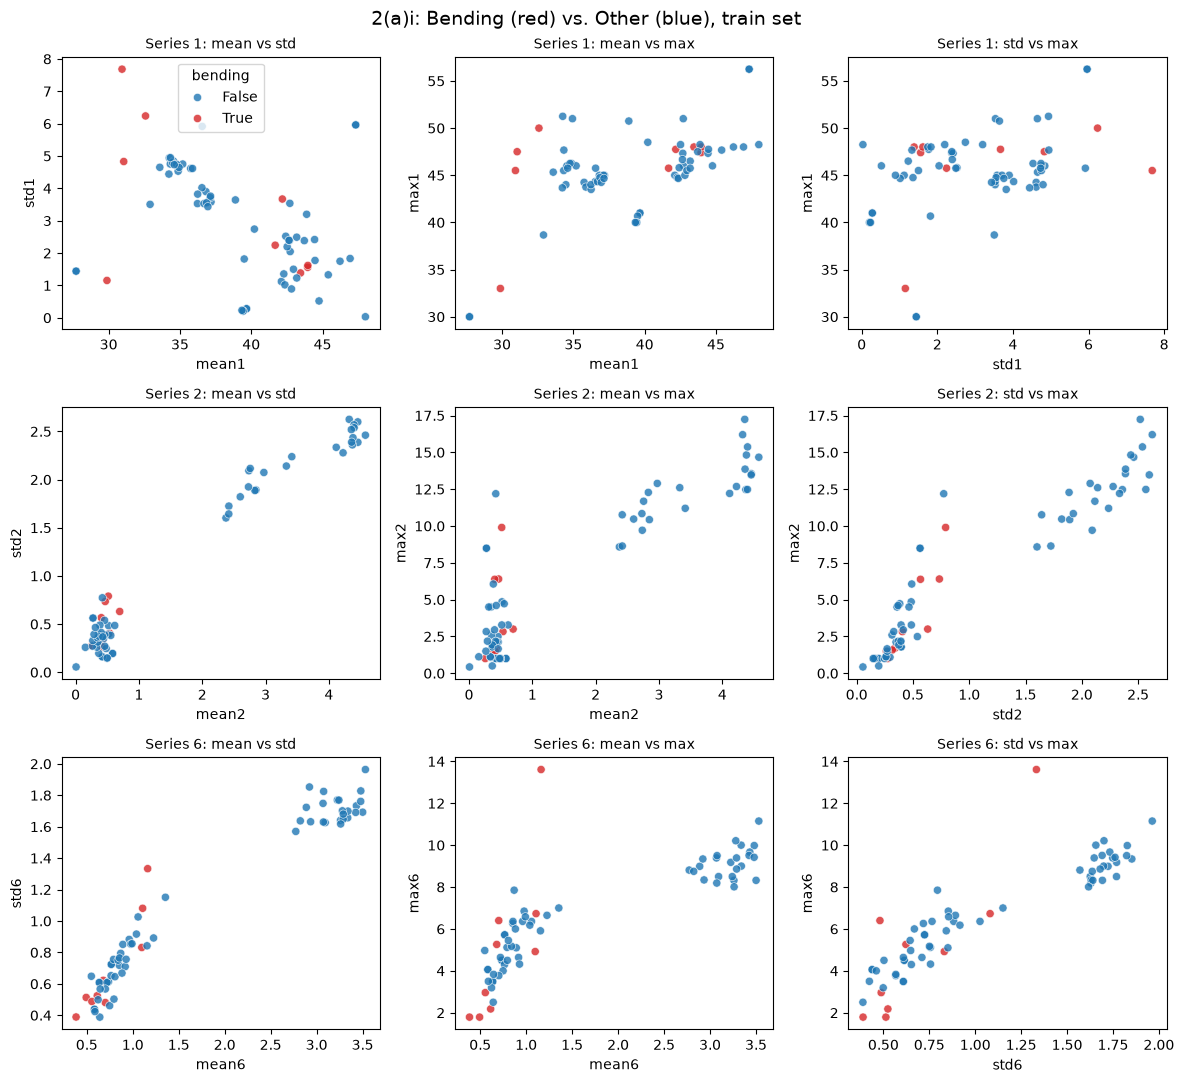

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns


train = features[features['split'] == 'train'].copy()


train['bending'] = train['activity'].str.startswith('bending')
print(train['bending'].value_counts())


chosen_stats  = ['mean', 'std', 'max']
chosen_series = [1, 2, 6]


pairs = [('mean', 'std'), ('mean', 'max'), ('std', 'max')]

fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for r, ts in enumerate(chosen_series):          
    for c, (fx, fy) in enumerate(pairs):        
        ax = axes[r, c]
        sns.scatterplot(data=train, x=f'{fx}{ts}', y=f'{fy}{ts}',
                        hue='bending', palette={True: 'tab:red', False: 'tab:blue'},
                        s=35, alpha=0.8, ax=ax, legend=(r == 0 and c == 0))
        ax.set_title(f'Series {ts}: {fx} vs {fy}', fontsize=10)

fig.suptitle('2(a)i: Bending (red) vs. Other (blue), train set', fontsize=14)
plt.tight_layout()
plt.show()

#### ii. Splitted Plots

(69, 88)


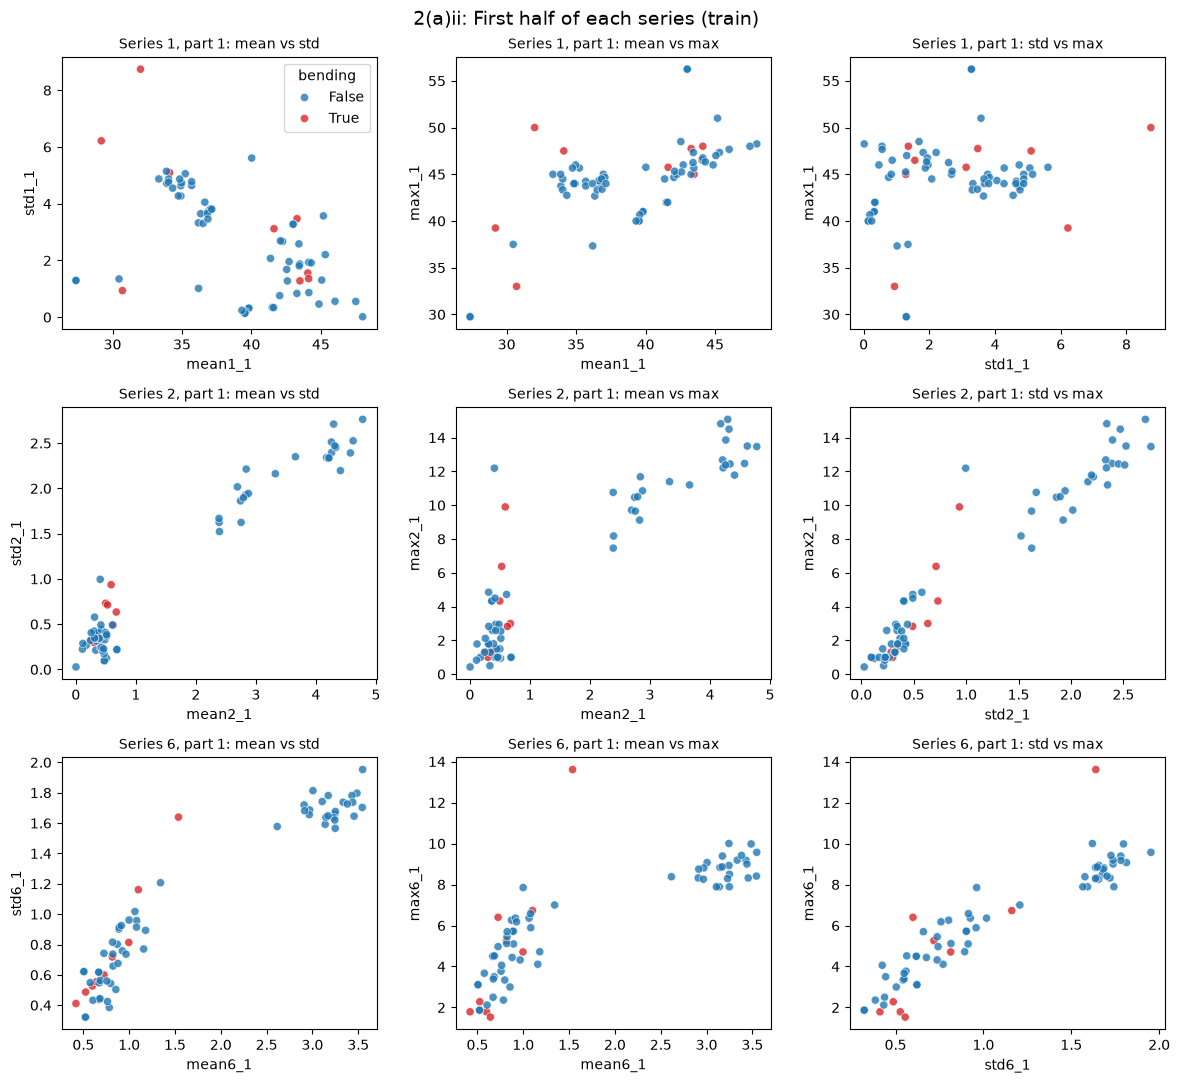

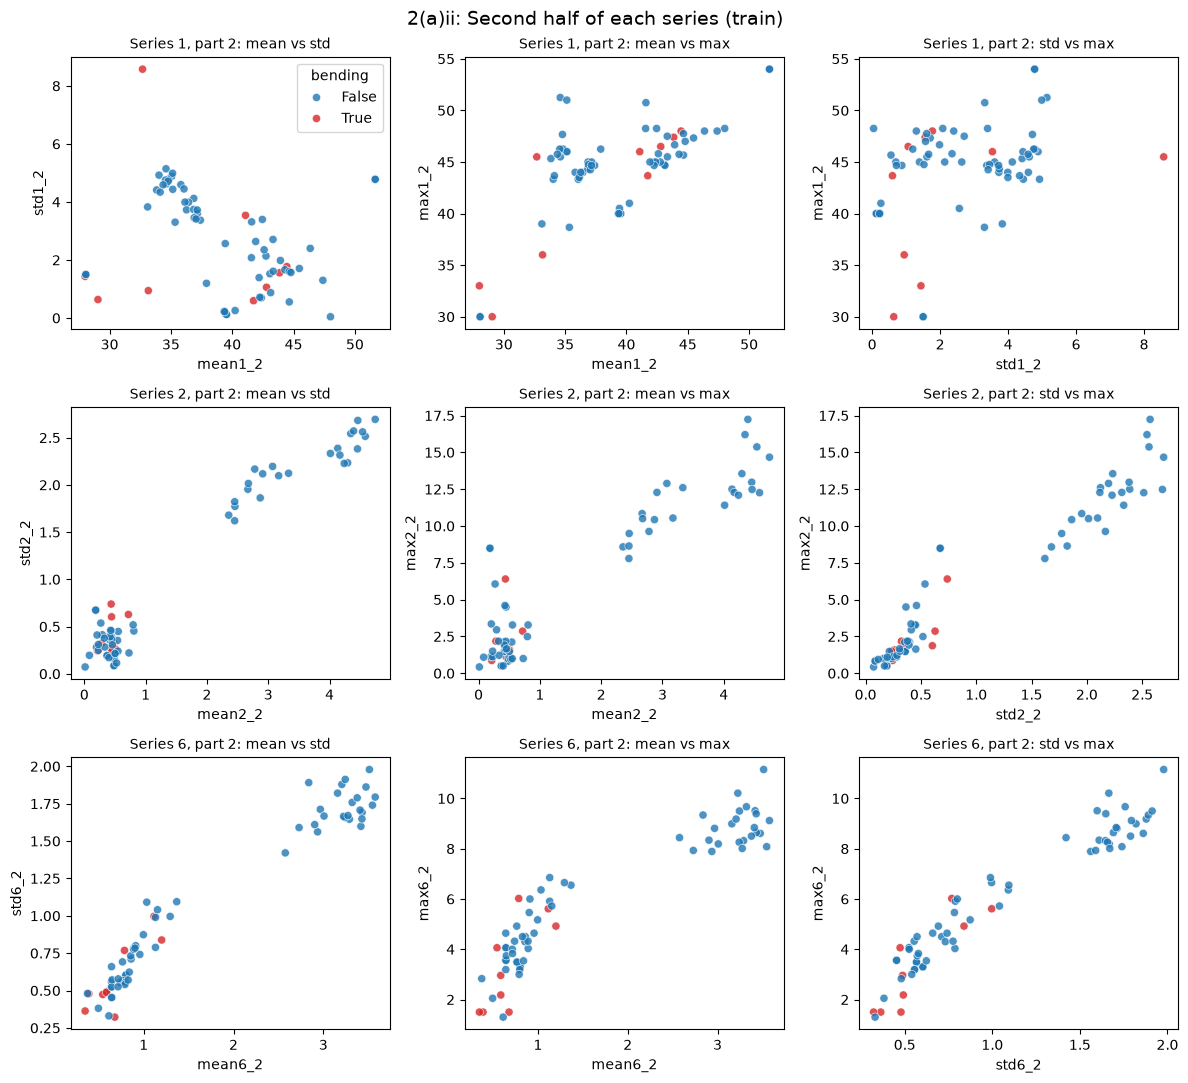

In [24]:
def extract_features(instances, l):
    """Split each of the 6 time series into l roughly equal parts
    and compute the 7 stats on every part."""
    rows = []
    for inst in instances:
        df = inst['data']
        row = {'activity': inst['activity'], 'num': inst['num'], 'split': inst['split']}
        for i, s in enumerate(series, start=1):
            parts = np.array_split(df[s].values, l)      
            for j, x in enumerate(parts, start=1):
                row[f'min{i}_{j}']       = np.min(x)
                row[f'max{i}_{j}']       = np.max(x)
                row[f'mean{i}_{j}']      = np.mean(x)
                row[f'median{i}_{j}']    = np.median(x)
                row[f'std{i}_{j}']       = np.std(x, ddof=1)
                row[f'1st_quart{i}_{j}'] = np.percentile(x, 25)
                row[f'3rd_quart{i}_{j}'] = np.percentile(x, 75)
        rows.append(row)
    out = pd.DataFrame(rows)
    out['bending'] = out['activity'].str.startswith('bending')
    return out


def plot_grid(df, part, title):
    """3x3 grid like 2(a)i, for one part (half) of the series."""
    fig, axes = plt.subplots(3, 3, figsize=(12, 11))
    for r, ts in enumerate(chosen_series):
        for c, (fx, fy) in enumerate(pairs):
            ax = axes[r, c]
            sns.scatterplot(data=df, x=f'{fx}{ts}_{part}', y=f'{fy}{ts}_{part}',
                            hue='bending', palette={True: 'tab:red', False: 'tab:blue'},
                            s=35, alpha=0.8, ax=ax, legend=(r == 0 and c == 0))
            ax.set_title(f'Series {ts}, part {part}: {fx} vs {fy}', fontsize=10)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()



feat2 = extract_features(instances, l=2)
train2 = feat2[feat2['split'] == 'train']
print(train2.shape)   

plot_grid(train2, part=1, title='2(a)ii: First half of each series (train)')
plot_grid(train2, part=2, title='2(a)ii: Second half of each series (train)')

#### iii. Time Series Segments

In [25]:
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
warnings.filterwarnings('ignore', category=ConvergenceWarning)

label_cols = ['activity', 'num', 'split', 'bending']
L_values   = range(1, 21)
max_p      = 20
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


feature_sets = {l: extract_features(instances, l) for l in L_values}

results = []
for l in L_values:
    tr = feature_sets[l][feature_sets[l]['split'] == 'train']
    X = tr.drop(columns=label_cols).values
    y = tr['bending'].astype(int).values

    fold_acc = np.zeros((5, max_p))
    for k, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
        
        scaler = StandardScaler().fit(X[tr_idx])
        X_tr, X_va = scaler.transform(X[tr_idx]), scaler.transform(X[va_idx])
        y_tr, y_va = y[tr_idx], y[va_idx]

        
        rfe = RFE(LogisticRegression(C=1e6, max_iter=200),
                  n_features_to_select=1, step=1).fit(X_tr, y_tr)
        order = np.argsort(rfe.ranking_)       

        for p in range(1, max_p + 1):
            keep = order[:p]                   
            clf = LogisticRegression(C=1e6, max_iter=200).fit(X_tr[:, keep], y_tr)
            fold_acc[k, p - 1] = clf.score(X_va[:, keep], y_va)

    for p in range(1, max_p + 1):
        results.append({'l': l, 'p': p, 'cv_acc': fold_acc[:, p - 1].mean()})

cv_results = pd.DataFrame(results)


best = cv_results.sort_values(['cv_acc', 'l', 'p'], ascending=[False, True, True]).iloc[0]
best_l, best_p = int(best['l']), int(best['p'])
print(f'Best (l, p) = ({best_l}, {best_p}),  CV accuracy = {best.cv_acc:.3f}')
cv_results.sort_values('cv_acc', ascending=False).head(10)

Best (l, p) = (1, 16),  CV accuracy = 0.986


,l,p,cv_acc
371,19,12,0.985714
369,19,10,0.985714
191,10,12,0.985714
190,10,11,0.985714
189,10,10,0.985714
187,10,8,0.985714
370,19,11,0.985714
19,1,20,0.985714
16,1,17,0.985714
15,1,16,0.985714


The wrong way to do cross validation for this problem is to wait until after RFE is conducted on the entire training set and the p features are selected. This is because model may choose features that don't have an impact, because it covers all data, including that which helped decide the features. The right way to conduct cross validation is to run RFE on 4 of the 5 folds, run logistic regression on those folds, and score it on the 5th fold, repeating for every fold. This is because that 5th fold didn't influence the features, so the validation score on it is more accurate. 

#### iv. Confusion Matrix

16 selected features: ['min1_1', 'max1_1', 'mean1_1', '3rd_quart1_1', 'max2_1', 'max3_1', '3rd_quart3_1', 'max4_1', 'median4_1', '1st_quart4_1', 'min5_1', 'max5_1', 'mean5_1', '1st_quart5_1', 'std6_1', '1st_quart6_1']


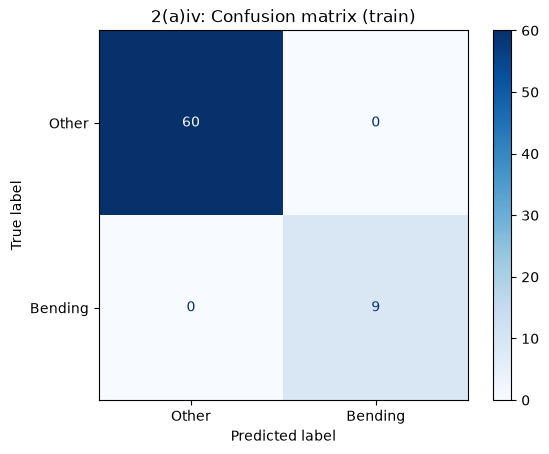

Train accuracy: 1.0


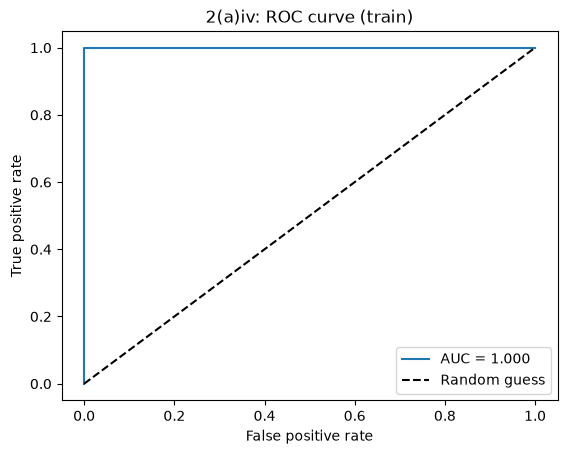

,beta (sklearn),beta (statsmodels),p-value
intercept,-10.9725,-28.4837,0.9997
min1_1,-1.9377,-6.6618,0.9999
max1_1,1.7090,6.8353,1.0000
mean1_1,-1.2392,8.0469,1.0000
3rd_quart1_1,-2.9257,-21.4953,1.0000
max2_1,-2.0479,-6.5102,1.0000
max3_1,0.7503,10.1601,1.0000
3rd_quart3_1,-2.2933,-4.4120,1.0000
max4_1,2.1734,10.0337,0.9999
median4_1,-1.1551,-2.5394,1.0000


In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, accuracy_score
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
warnings.filterwarnings('ignore', category=PerfectSeparationWarning)
warnings.filterwarnings('ignore', category=sm.tools.sm_exceptions.ConvergenceWarning)


df_best   = extract_features(instances, best_l)
tr_best   = df_best[df_best['split'] == 'train']
feat_names = tr_best.drop(columns=label_cols).columns
X_train   = tr_best.drop(columns=label_cols).values
y_train   = tr_best['bending'].astype(int).values


scaler_best = StandardScaler().fit(X_train)
X_train_s   = scaler_best.transform(X_train)

rfe_best = RFE(LogisticRegression(C=1e6, max_iter=200),
               n_features_to_select=best_p, step=1).fit(X_train_s, y_train)
selected = feat_names[rfe_best.support_]
X_sel    = X_train_s[:, rfe_best.support_]
print(f'{best_p} selected features:', list(selected))


model  = LogisticRegression(C=1e6, max_iter=200).fit(X_sel, y_train)
y_pred = model.predict(X_sel)
y_prob = model.predict_proba(X_sel)[:, 1]     


ConfusionMatrixDisplay(confusion_matrix(y_train, y_pred),
                       display_labels=['Other', 'Bending']).plot(cmap='Blues')
plt.title('2(a)iv: Confusion matrix (train)')
plt.show()
print('Train accuracy:', accuracy_score(y_train, y_pred))


fpr, tpr, _ = roc_curve(y_train, y_prob)
auc = roc_auc_score(y_train, y_prob)
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('2(a)iv: ROC curve (train)'); plt.legend()
plt.show()


X_sm = sm.add_constant(pd.DataFrame(X_sel, columns=selected))
sm_model = sm.Logit(y_train, X_sm).fit(disp=0)

coef_table = pd.DataFrame({
    'beta (sklearn)': np.r_[model.intercept_, model.coef_[0]],
    'beta (statsmodels)': sm_model.params.values,
    'p-value': sm_model.pvalues.values,
}, index=['intercept'] + list(selected))
coef_table.round(4)

#### v. Test Classifier

Test set: 19 instances, 4 bending


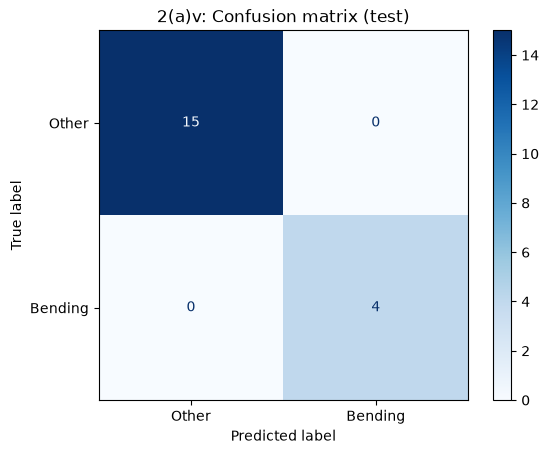

Test accuracy: 1.000
CV accuracy:   0.986


In [27]:

te_best = df_best[df_best['split'] == 'test']
X_test  = te_best.drop(columns=label_cols).values
y_test  = te_best['bending'].astype(int).values
print(f'Test set: {len(y_test)} instances, {y_test.sum()} bending')


X_test_sel = scaler_best.transform(X_test)[:, rfe_best.support_]


y_test_pred = model.predict(X_test_sel)
test_acc = accuracy_score(y_test, y_test_pred)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred),
                       display_labels=['Other', 'Bending']).plot(cmap='Blues')
plt.title('2(a)v: Confusion matrix (test)')
plt.show()

print(f'Test accuracy: {test_acc:.3f}')
print(f'CV accuracy:   {best.cv_acc:.3f}')

#### vi. Separation

Yes, the classes look like they are completely separated, with a number of things showing this. First, the training confusion matrix is 100% correct, with train and AUC accuracy both at 1.0. Also, p-values for each feature were either 1 or very close to it, and betas varied across sklearn and stats models, yet still provide accurate predicitons. Finally, on test data, we see perfect accuracy again, and CV accuracy is nearly perfect. Perfectly seperated classes causes beta to get more accurate as it grows, meaning there is no maximum likelihood value, causing instability in calculating log. regression parameters. 

#### vii. Imbalance

Case-control sample: 9 cases + 27 controls = 36 rows
pi = 0.130,  pi_tilde = 0.250,  intercept adjustment = -0.799
Intercept before: -7.731
Intercept after:  -8.529


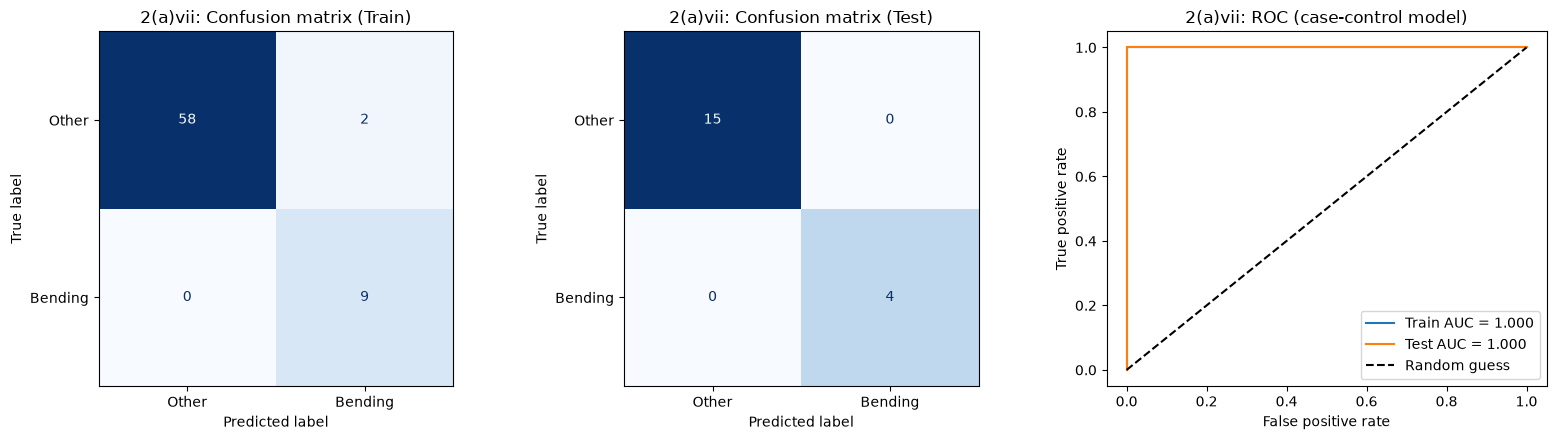

In [28]:
rng = np.random.default_rng(42)
case_idx    = np.where(y_train == 1)[0]
control_idx = np.where(y_train == 0)[0]

ratio = 3
sampled_controls = rng.choice(control_idx, size=ratio * len(case_idx), replace=False)
cc_idx = np.concatenate([case_idx, sampled_controls])

X_cc, y_cc = X_sel[cc_idx], y_train[cc_idx]
print(f'Case-control sample: {y_cc.sum()} cases + {(y_cc == 0).sum()} controls = {len(y_cc)} rows')

model_cc = LogisticRegression(C=1e6, max_iter=200).fit(X_cc, y_cc)

pi       = y_train.mean()
pi_tilde = y_cc.mean()
adjust   = np.log(pi / (1 - pi)) - np.log(pi_tilde / (1 - pi_tilde))

print(f'pi = {pi:.3f},  pi_tilde = {pi_tilde:.3f},  intercept adjustment = {adjust:.3f}')
print(f'Intercept before: {model_cc.intercept_[0]:.3f}')
model_cc.intercept_ = model_cc.intercept_ + adjust
print(f'Intercept after:  {model_cc.intercept_[0]:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, X_, y_) in zip(axes[:2], [('Train', X_sel, y_train), ('Test', X_test_sel, y_test)]):
    ConfusionMatrixDisplay(confusion_matrix(y_, model_cc.predict(X_)),
                           display_labels=['Other', 'Bending']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'2(a)vii: Confusion matrix ({name})')

for name, X_, y_ in [('Train', X_sel, y_train), ('Test', X_test_sel, y_test)]:
    prob = model_cc.predict_proba(X_)[:, 1]
    fpr, tpr, _ = roc_curve(y_, prob)
    axes[2].plot(fpr, tpr, label=f'{name} AUC = {roc_auc_score(y_, prob):.3f}')
axes[2].plot([0, 1], [0, 1], 'k--', label='Random guess')
axes[2].set_xlabel('False positive rate'); axes[2].set_ylabel('True positive rate')
axes[2].set_title('2(a)vii: ROC (case-control model)'); axes[2].legend()
plt.tight_layout()
plt.show()

The confusion matrixes show imbalance in classes, with only 9 bending vs. 60 other in the training data, and 4 bending vs. 15 other in the test data. 

I kept all 9 bending cases and sampled 3 controls per case (27 of the 60 other instances) for a more stable fit than a 1:1 sample would give. This was accounted for in the code to adjust the intercept. 

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Best l = 1,  C = 2.3357,  CV accuracy = 0.971
8 features kept by L1: ['3rd_quart1_1', 'max2_1', '1st_quart3_1', '1st_quart4_1', 'min5_1', 'max5_1', '1st_quart5_1', '1st_quart6_1']


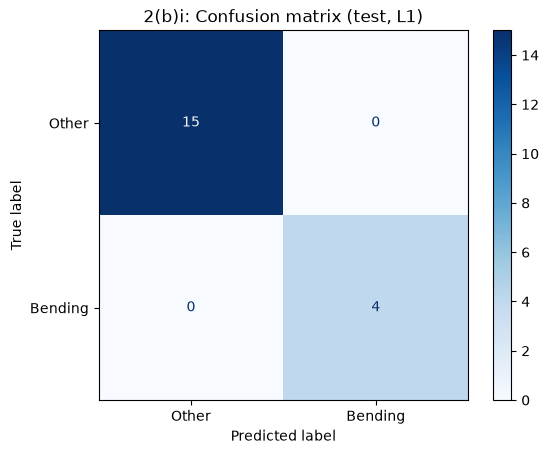

Train accuracy: 1.000
Test accuracy:  1.000


,l,best_C,cv_acc
0,1,2.336,0.971
1,2,14.384,0.971
2,3,0.379,0.957
3,4,0.379,0.957
4,5,14.384,0.942
5,6,14.384,0.957
6,7,48.329,0.956
7,8,48.329,0.943
8,9,2.336,0.942
9,10,48.329,0.971


In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

C_grid = np.logspace(-2, 3, 20)

l1_results = []
for l in L_values:
    tr = feature_sets[l][feature_sets[l]['split'] == 'train']
    X = tr.drop(columns=label_cols).values
    y = tr['bending'].astype(int).values

    pipe = make_pipeline(StandardScaler(),
                         LogisticRegression(l1_ratio=1, solver='liblinear', max_iter=1000))
    grid = GridSearchCV(pipe, {'logisticregression__C': C_grid}, cv=skf, scoring='accuracy')
    grid.fit(X, y)

    l1_results.append({'l': l,
                       'best_C': grid.best_params_['logisticregression__C'],
                       'cv_acc': grid.best_score_})

l1_cv = pd.DataFrame(l1_results)
best_l1 = l1_cv.sort_values(['cv_acc', 'l'], ascending=[False, True]).iloc[0]
l1_l, l1_C = int(best_l1['l']), best_l1['best_C']
print(f'Best l = {l1_l},  C = {l1_C:.4f},  CV accuracy = {best_l1.cv_acc:.3f}')

df_l1 = feature_sets[l1_l]
tr_l1, te_l1 = df_l1[df_l1['split'] == 'train'], df_l1[df_l1['split'] == 'test']
X_tr_l1, y_tr_l1 = tr_l1.drop(columns=label_cols).values, tr_l1['bending'].astype(int).values
X_te_l1, y_te_l1 = te_l1.drop(columns=label_cols).values, te_l1['bending'].astype(int).values

model_l1 = make_pipeline(StandardScaler(),
                         LogisticRegression(l1_ratio=1, solver='liblinear', C=l1_C, max_iter=1000))
model_l1.fit(X_tr_l1, y_tr_l1)

coefs = model_l1[-1].coef_[0]
kept  = tr_l1.drop(columns=label_cols).columns[coefs != 0]
print(f'{len(kept)} features kept by L1:', list(kept))

ConfusionMatrixDisplay(confusion_matrix(y_te_l1, model_l1.predict(X_te_l1)),
                       display_labels=['Other', 'Bending']).plot(cmap='Blues')
plt.title('2(b)i: Confusion matrix (test, L1)')
plt.show()
print(f'Train accuracy: {accuracy_score(y_tr_l1, model_l1.predict(X_tr_l1)):.3f}')
print(f'Test accuracy:  {accuracy_score(y_te_l1, model_l1.predict(X_te_l1)):.3f}')
l1_cv.round(3)

#### ii. Comparison

In (a)iii, I used backward selection with RFE to select features, and this proved to have similar results to the L1-penalized regression method. Both chose l=1, got 100% training and test accuracy, and had a very similar CV accuracy (L1 with .971 and RFE with .986). Though the results of RFE may be slightly better due to the CV value, the coefficients for the L1 were stabilized wheras the p-values for the p-value approach were all 1, meaning they were essentially unusable. L1 also used only 8 features compared to 16 to reach similar accuracy. 

The L1 method was also easier to implement, because feature selection was built into the model regression fit, with only C, the budget of the penalty, having to be tuned. The other method required RFE as it's own step to select features, a manual cross validation loop, and the recording of p-values. 

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packa

Best l = 2,  C = 1.6681,  CV accuracy = 0.914
Test error: 0.158


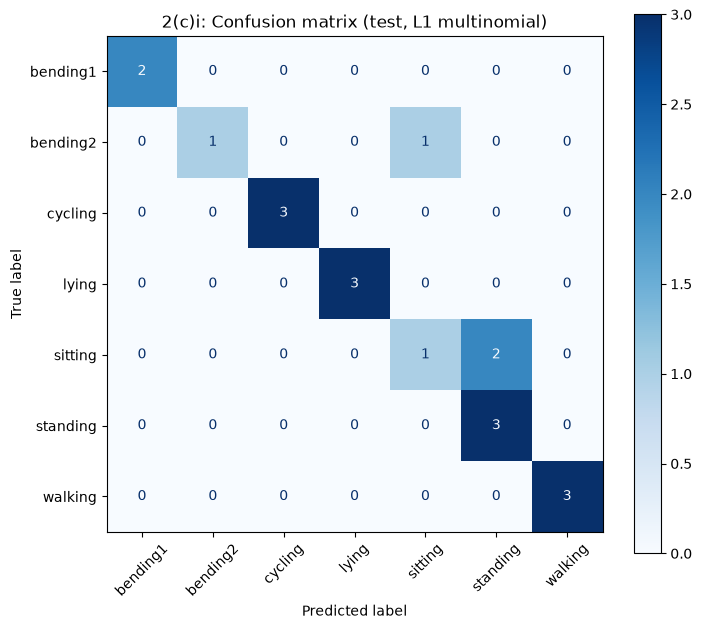

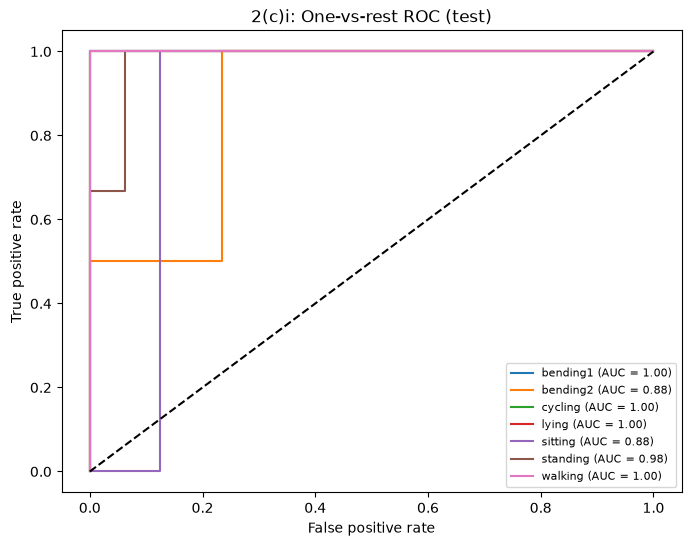

Macro-average AUC: 0.962


,l,best_C,cv_acc
0,1,5.995,0.913
1,2,1.668,0.914
2,3,5.995,0.842
3,4,21.544,0.856
4,5,77.426,0.870
5,6,77.426,0.842
6,7,278.256,0.842
7,8,5.995,0.856
8,9,1.668,0.856
9,10,278.256,0.826


In [30]:
from sklearn.preprocessing import label_binarize

C_grid_mc = np.logspace(-2, 3, 10)

mc_results = []
for l in L_values:
    tr = feature_sets[l][feature_sets[l]['split'] == 'train']
    X = tr.drop(columns=label_cols).values
    y = tr['activity'].values

    pipe = make_pipeline(StandardScaler(),
                         LogisticRegression(l1_ratio=1, solver='saga', max_iter=5000))
    grid = GridSearchCV(pipe, {'logisticregression__C': C_grid_mc},
                        cv=skf, scoring='accuracy', n_jobs=-1)
    grid.fit(X, y)

    mc_results.append({'l': l,
                       'best_C': grid.best_params_['logisticregression__C'],
                       'cv_acc': grid.best_score_})

mc_cv = pd.DataFrame(mc_results)
best_mc = mc_cv.sort_values(['cv_acc', 'l'], ascending=[False, True]).iloc[0]
mc_l, mc_C = int(best_mc['l']), best_mc['best_C']
print(f'Best l = {mc_l},  C = {mc_C:.4f},  CV accuracy = {best_mc.cv_acc:.3f}')

df_mc = feature_sets[mc_l]
tr_mc, te_mc = df_mc[df_mc['split'] == 'train'], df_mc[df_mc['split'] == 'test']
X_tr_mc, y_tr_mc = tr_mc.drop(columns=label_cols).values, tr_mc['activity'].values
X_te_mc, y_te_mc = te_mc.drop(columns=label_cols).values, te_mc['activity'].values

model_mc = make_pipeline(StandardScaler(),
                         LogisticRegression(l1_ratio=1, solver='saga', C=mc_C, max_iter=5000))
model_mc.fit(X_tr_mc, y_tr_mc)

y_te_pred = model_mc.predict(X_te_mc)
mc_test_err = 1 - accuracy_score(y_te_mc, y_te_pred)
print(f'Test error: {mc_test_err:.3f}')

classes = model_mc.classes_
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_te_mc, y_te_pred, labels=classes),
                       display_labels=classes).plot(ax=ax, cmap='Blues', xticks_rotation=45)
ax.set_title('2(c)i: Confusion matrix (test, L1 multinomial)')
plt.show()

y_te_bin = label_binarize(y_te_mc, classes=classes)
y_te_prob = model_mc.predict_proba(X_te_mc)

plt.figure(figsize=(8, 6))
for k, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_te_bin[:, k], y_te_prob[:, k])
    plt.plot(fpr, tpr, label=f'{cls} (AUC = {roc_auc_score(y_te_bin[:, k], y_te_prob[:, k]):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('2(c)i: One-vs-rest ROC (test)')
plt.legend(fontsize=8)
plt.show()
print(f"Macro-average AUC: {roc_auc_score(y_te_mc, y_te_prob, multi_class='ovr', labels=classes):.3f}")
mc_cv.round(3)

#### ii. Naive Bayes

Gaussian NB: best l = 1,  CV accuracy = 0.857,  test error = 0.105


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packa

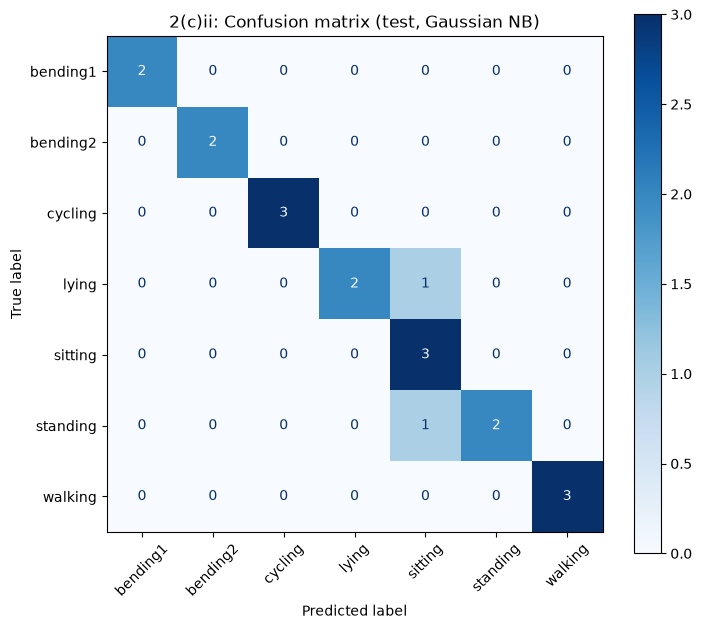

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Multinomial NB: best l = 1,  CV accuracy = 0.855,  test error = 0.105


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packa

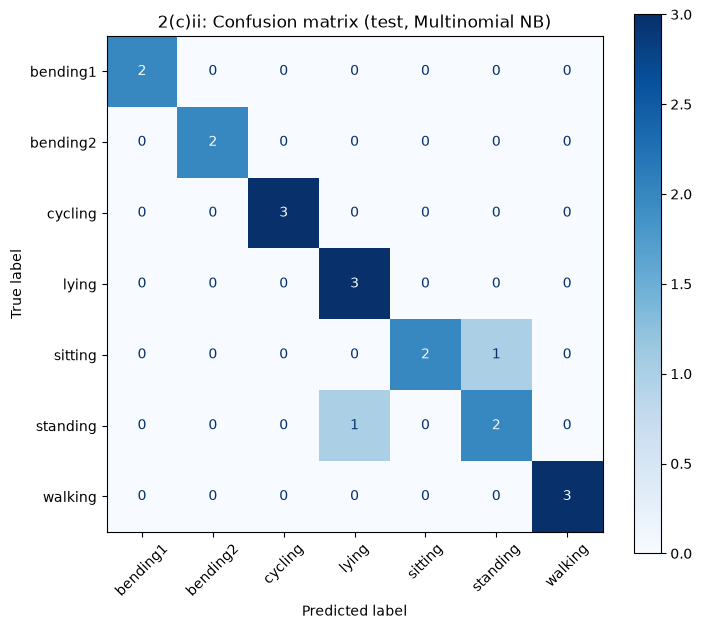

,model,best_l,cv_acc,test_error
0,L1 multinomial LR,2,0.914,0.158
1,Gaussian NB,1,0.857,0.105
2,Multinomial NB,1,0.855,0.105


In [31]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score

def nb_select_and_test(make_model, name):
    rows = []
    for l in L_values:
        tr = feature_sets[l][feature_sets[l]['split'] == 'train']
        X = tr.drop(columns=label_cols).values
        y = tr['activity'].values
        rows.append({'l': l, 'cv_acc': cross_val_score(make_model(), X, y, cv=skf).mean()})
    cv_df = pd.DataFrame(rows)
    best = cv_df.sort_values(['cv_acc', 'l'], ascending=[False, True]).iloc[0]
    l_best = int(best['l'])

    df = feature_sets[l_best]
    tr, te = df[df['split'] == 'train'], df[df['split'] == 'test']
    model = make_model().fit(tr.drop(columns=label_cols).values, tr['activity'].values)
    y_te = te['activity'].values
    y_pred = model.predict(te.drop(columns=label_cols).values)
    test_err = 1 - accuracy_score(y_te, y_pred)
    print(f'{name}: best l = {l_best},  CV accuracy = {best.cv_acc:.3f},  test error = {test_err:.3f}')

    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=model.classes_),
                           display_labels=model.classes_).plot(ax=ax, cmap='Blues', xticks_rotation=45)
    ax.set_title(f'2(c)ii: Confusion matrix (test, {name})')
    plt.show()
    return {'model': name, 'best_l': l_best, 'cv_acc': best.cv_acc, 'test_error': test_err}

gnb_res = nb_select_and_test(GaussianNB, 'Gaussian NB')
mnb_res = nb_select_and_test(MultinomialNB, 'Multinomial NB')

pd.DataFrame([
    {'model': 'L1 multinomial LR', 'best_l': mc_l, 'cv_acc': best_mc.cv_acc, 'test_error': mc_test_err},
    gnb_res,
    mnb_res,
]).round(3)

#### ii. Comparison

Gaussian and Multinomial NB produce almost identical results, with the CV score favoring Gaussian by only .002. In principle, Gaussian is more applicable here because the features are continuous, but in practice they could be interchanged. While the Naive Bayes models only misclassified 2 out of 19 as opposed to the multinomial regression model's 3, the CV score tells a different story. With a score of .914 instead of .857, the multinomial regression model is the favorite for this dataset, since that CV score is based on all 69 rows, and is a more significant indicator of accuracy than the 1 classification difference. 

## 3. ISLR 4.8.3

There is one feature x and K classes. In class k, x follows a normal distribution with mean μk and its own variance σk^2. Each class also has a prior probability πk, the share of observations that belong to class k.

The Bayes classifier assigns x to the class with the highest posterior probability pk(x), the probability that x came from class k. By Bayes' theorem:
pk(x) = πk·fk(x) / (sum over all classes of πl·fl(x))
where fₖ(x) is the normal density of class k (how typical the value x is for class k). The denominator is the same for every class, so the class with the largest pk(x) is also the class with the largest πk·fk(x).

Taking the log does not change which class is largest, and it removes the exponential in the normal density. Dropping the terms that are identical for every class leaves the discriminant function:
δk(x) = log(πk) − log(σk) − (x − μk)^2 / (2σk^2)
the classifier picks the class with the largest δk(x).

Since (x − μk)^2 = x^2 − 2μkx + μk^2:

δk(x) = −x^2 / (2σk^2) + (μk / σk^2)·x − μk^2 / (2σk^2) + log(πk) − log(σk)

So δk(x) contains an x^2 term, an x term, and a constant.

In LDA (Section 4.4.1), all classes share the same variance σ^2. Then the x^2 term, −x^2 / (2σ^2), is the same for every class. Adding the same amount to every class's score cannot change which class wins, so it can be dropped, and δk(x) becomes linear in x. That is why LDA is linear.

Here each class has its own σk^2, so the x^2 term −x^2 / (2σk^2) is different for each class and cannot be dropped. Each δk(x) is therefore a quadratic function of x. The decision boundary between classes k and j is where δk(x) = δj(x). Its x^2 coefficient is

1/(2σj^2) − 1/(2σk^2)

which is nonzero whenever σk doesn't equal σj. So the boundary is the solution of a quadratic equation, not a linear one.




## 4. ISLR 4.8.7

- Companies that issued a dividend ("Yes"): mean profit = 10
- Companies that did not ("No"): mean profit = 0
- Variance of profit in both groups: 36 (standard deviation = 6)
- Share of companies that issued a dividend: 80%, so the prior for "Yes" is 0.8 and the prior for "No" is 0.2
- The company we're predicting had a profit of X = 4

Bayes' theorem gives the probability of a dividend given the profit x. It weights how common each group is  by how typical x is for that group (the density), then divides by the total for both groups:

p_Yes(x) = (π_Yes · f_Yes(x)) / (π_Yes · f_Yes(x) + π_No · f_No(x))

Density is how typical a profit of 4 is for that group, measured with the normal (bell curve) density centered at that group's mean.

f_k(x) = 1 / (sqr(2π) · σ) · exp( −(x − μ_k)^2 / (2σ^2) )

Both groups have the same variance, so the constant part of the normal density is identical for Yes and No and cancels out. Only the exponential part matters, and it depends on how far 4 is from each group's mean:
- Yes: 4 is 6 away from the mean of 10, which gives e^(−36/72) = e^(−0.5) ≈ 0.6065
- No: 4 is 4 away from the mean of 0, which gives e^(−16/72) = e^(−0.222) ≈ 0.8007

- Yes: 0.8 × 0.6065 ≈ 0.4852
- No: 0.2 × 0.8007 ≈ 0.1601

Divide the Yes weight by the total of both weights:

0.4852 / (0.4852 + 0.1601) = 0.4852 / 0.6454 ≈ 0.752

I used Claude as a learning aid for this assignment- explanations of the concepts (cross-validation, separation, case-control sampling, L1 regularization, Naive Bayes, Bayes’ theorem), help writing and debugging the code in Part 2, and help structuring the written answers to Problems 3 and 4.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9